In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

Matplotlib is building the font cache; this may take a moment.


In [2]:
df = pd.read_csv("../data/fraudTrain.csv", parse_dates=["trans_date_trans_time"])
print(df.shape)
df.head()

(1296675, 23)


,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,city,state,zip,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,Moravian Falls,NC,28654,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0
1,1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,Orient,WA,99160,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0
2,2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,Malad City,ID,83252,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0
3,3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,Boulder,MT,59632,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0
4,4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,Doe Hill,VA,24433,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0


In [3]:
df = df.drop(columns=["Unnamed: 0"])

In [4]:
df.head()

,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,city,state,zip,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,Moravian Falls,NC,28654,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0
1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,Orient,WA,99160,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0
2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,Malad City,ID,83252,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0
3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,Boulder,MT,59632,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0
4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,Doe Hill,VA,24433,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0


In [12]:
print(df.dtypes)
print("\nMissing values:\n", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

trans_date_trans_time    datetime64[us]
cc_num                            int64
merchant                            str
category                            str
amt                             float64
first                               str
last                                str
gender                              str
street                              str
city                                str
state                               str
zip                               int64
lat                             float64
long                            float64
city_pop                          int64
job                                 str
dob                                 str
trans_num                           str
unix_time                         int64
merch_lat                       float64
merch_long                      float64
is_fraud                          int64
hour                              int32
dtype: object

Missing values:
 0
Duplicate rows: 0


In [6]:
print(df["is_fraud"].value_counts())
print(f"Fraud rate: {df['is_fraud'].mean():.2%}")

is_fraud
0    1289169
1       7506
Name: count, dtype: int64
Fraud rate: 0.58%


              count        mean         std   min       25%      50%      75%  \
is_fraud                                                                        
0         1289169.0   67.667110  154.007971  1.00    9.6100   47.280   82.540   
1            7506.0  531.320092  390.560070  1.06  245.6625  396.505  900.875   

               max  
is_fraud            
0         28948.90  
1          1376.04  


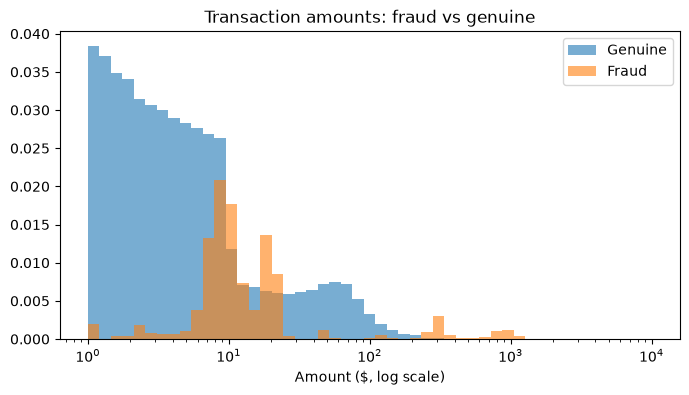

In [17]:
print(df.groupby("is_fraud")["amt"].describe())

bins = np.logspace(0, 4, 50)
plt.figure(figsize=(8, 4))
plt.hist(df.loc[df.is_fraud == 0, "amt"], bins=bins, alpha=0.6, density=True, label="Genuine")
plt.hist(df.loc[df.is_fraud == 1, "amt"], bins=bins, alpha=0.6, density=True, label="Fraud")
plt.xscale("log"); plt.xlabel("Amount ($, log scale)"); plt.legend()
plt.title("Transaction amounts: fraud vs genuine")
plt.savefig("../images/amount_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

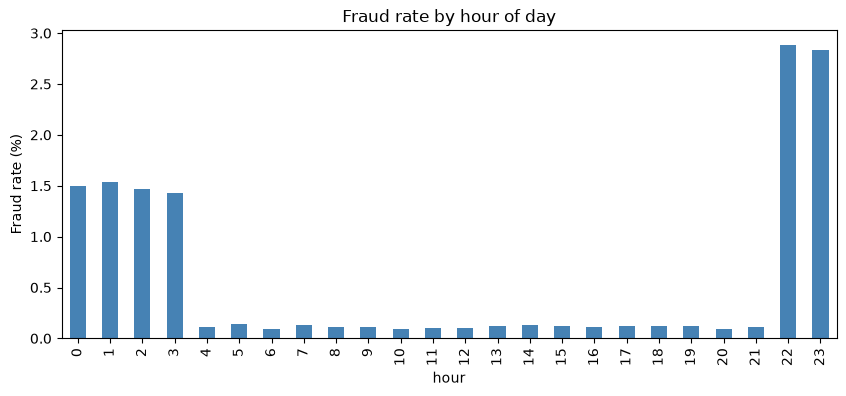

In [8]:
df["hour"] = df["trans_date_trans_time"].dt.hour
rate_by_hour = df.groupby("hour")["is_fraud"].mean() * 100

rate_by_hour.plot(kind="bar", figsize=(10, 4), color="steelblue")
plt.ylabel("Fraud rate (%)"); plt.title("Fraud rate by hour of day")
plt.savefig("../images/fraud_by_hour.png", dpi=150, bbox_inches="tight")
plt.show()

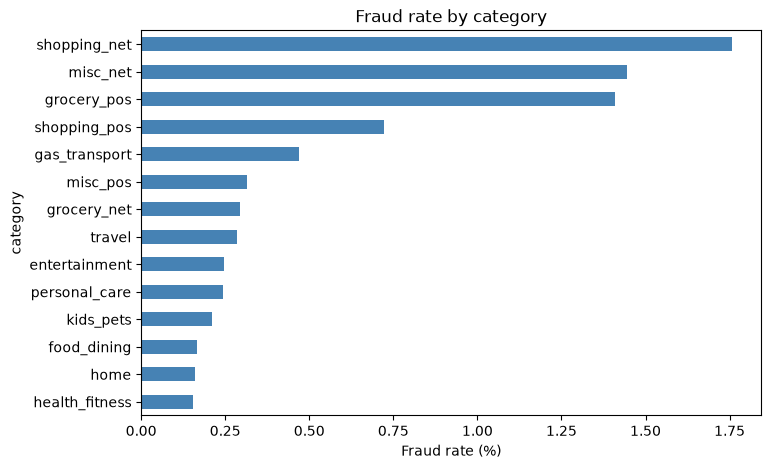

In [9]:
rate_by_cat = df.groupby("category")["is_fraud"].mean().sort_values() * 100

rate_by_cat.plot(kind="barh", figsize=(8, 5), color="steelblue")
plt.xlabel("Fraud rate (%)"); plt.title("Fraud rate by category")
plt.savefig("../images/fraud_by_category.png", dpi=150, bbox_inches="tight")
plt.show()

In [10]:
fraud_money = df.loc[df.is_fraud == 1, "amt"].sum()
total_money = df["amt"].sum()
print(f"Fraud: ${fraud_money:,.0f} of ${total_money:,.0f} ({fraud_money/total_money:.2%} of all money)")

Fraud: $3,988,089 of $91,222,429 (4.37% of all money)
